In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('HDFC-RSE.csv')

# Rename columns
df.columns = ['Date', 'NAV']

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Sort the DataFrame by the 'Date' column in ascending order
df = df.sort_values(by='Date')
# Reindex, otherwise index values will be in the reverse
df = df.set_index(pd.RangeIndex(1, len(df) + 1))
print(df)


           Date     NAV
1    2016-02-26   9.997
2    2016-02-29  10.017
3    2016-03-01  10.196
4    2016-03-02  10.362
5    2016-03-03  10.478
...         ...     ...
2048 2024-06-24  54.273
2049 2024-06-25  54.589
2050 2024-06-26  54.545
2051 2024-06-27  54.528
2052 2024-06-28  54.463

[2052 rows x 2 columns]


          Date     NAV
0   2016-02-29   9.997
1   2016-03-31  10.196
2   2016-04-30  10.997
3   2016-05-31  11.351
4   2016-06-30  11.797
..         ...     ...
96  2024-02-29  47.776
97  2024-03-31  48.876
98  2024-04-30  49.494
99  2024-05-31  50.750
100 2024-06-30  52.509

[101 rows x 2 columns]
          Date     NAV Formatted_Date
0   2016-02-29   9.997     01-02-2016
1   2016-03-31  10.196     01-03-2016
2   2016-04-30  10.997     01-04-2016
3   2016-05-31  11.351     01-05-2016
4   2016-06-30  11.797     01-06-2016
..         ...     ...            ...
96  2024-02-29  47.776     01-02-2024
97  2024-03-31  48.876     01-03-2024
98  2024-04-30  49.494     01-04-2024
99  2024-05-31  50.750     01-05-2024
100 2024-06-30  52.509     01-06-2024

[101 rows x 3 columns]
<class 'pandas.DataFrame'>
DatetimeIndex: 101 entries, 2016-02-01 to 2024-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   NAV     101 non-null    float

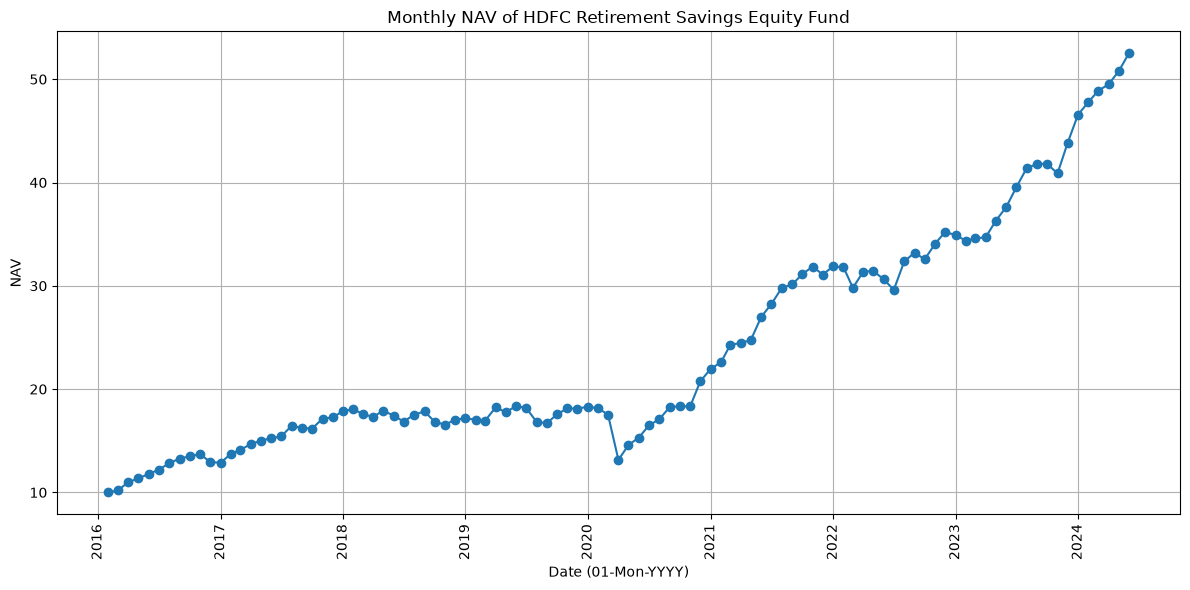

In [6]:

# Resample to 'M' (month) frequency and get the first record of each month
monthly_df = df.resample('ME', on='Date')['NAV'].first().reset_index()
print(monthly_df)

# Change the date to 01-Mon-yyyy format
monthly_df['Formatted_Date'] = monthly_df['Date'].dt.strftime('01-%m-%Y')
print(monthly_df)

# Rename Formatted_Date column as Date
monthly_df = monthly_df.drop('Date', axis=1)
monthly_df = monthly_df.rename(columns={'Formatted_Date': 'Date'})  # Rename column
monthly_df['Date'] = pd.to_datetime(monthly_df['Date'], dayfirst=True)
monthly_df = monthly_df.set_index('Date')
print(monthly_df.info())
print(monthly_df)

# Plot the monthly NAVs
plt.figure(figsize=(12, 6))
plt.plot(monthly_df.index, monthly_df['NAV'], marker='o', linestyle='-')
plt.xlabel('Date (01-Mon-YYYY)')
plt.ylabel('NAV')
plt.title('Monthly NAV of HDFC Retirement Savings Equity Fund')
plt.grid(True)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



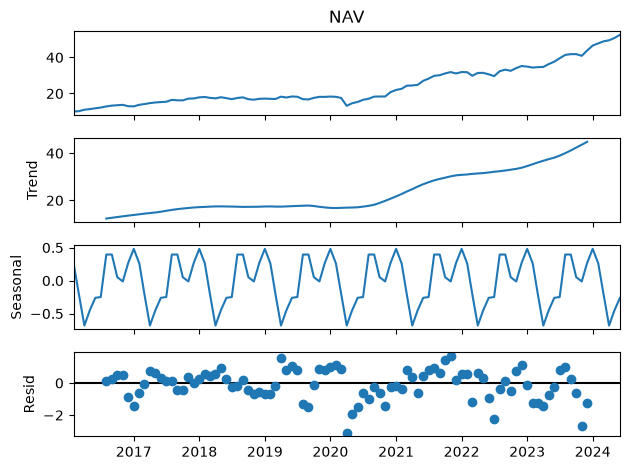

Date
2016-02-01          NaN
2016-03-01          NaN
2016-04-01          NaN
2016-05-01          NaN
2016-06-01          NaN
                ...    
2024-02-01    40.562750
2024-03-01    41.753500
2024-04-01    42.985917
2024-05-01    44.190667
2024-06-01    45.431333
Name: rollMean, Length: 101, dtype: float64
Date
2016-02-01         NaN
2016-03-01         NaN
2016-04-01         NaN
2016-05-01         NaN
2016-06-01         NaN
                ...   
2024-02-01    4.269050
2024-03-01    4.440092
2024-04-01    4.357505
2024-05-01    4.337313
2024-06-01    4.415862
Name: rollStd, Length: 101, dtype: float64


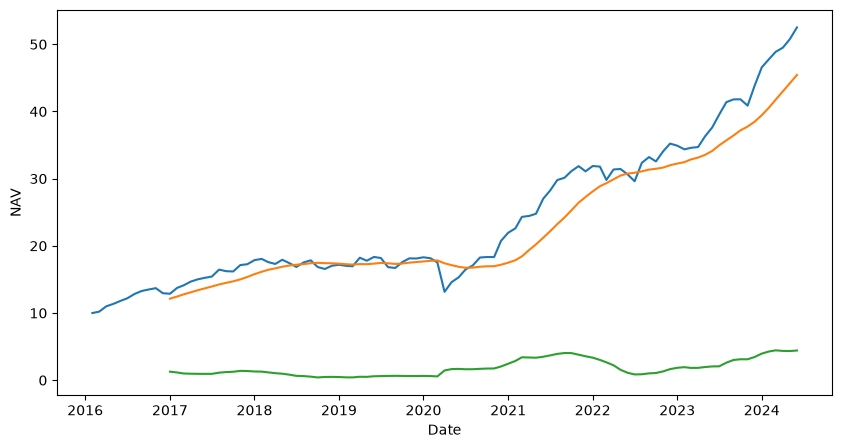

In [10]:
# Check for seasonality and trend
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(monthly_df.NAV, period=12)
fig = decomposition.plot()
plt.show()

# Calculate and plot rolling mean and standard deviation for 12 months
monthly_df['rollMean']  = monthly_df.NAV.rolling(window=12).mean()
monthly_df['rollStd']  = monthly_df.NAV.rolling(window=12).std()

print (monthly_df['rollMean'])
print (monthly_df['rollStd'])

plt.figure(figsize=(10,5))
sns.lineplot(data=monthly_df,x=monthly_df.index,y=monthly_df.NAV)
sns.lineplot(data=monthly_df,x=monthly_df.index,y=monthly_df.rollMean)
sns.lineplot(data=monthly_df,x=monthly_df.index,y=monthly_df.rollStd)
plt.show()
# Conclusion: Mean is not stationary, SD is stationary; so our data is not stationary

In [11]:


# ADF test ... H0: Data is not stationary
from statsmodels.tsa.stattools import adfuller
adfTest = adfuller(monthly_df['NAV'])

print(adfTest) # Let us interpret these values below by converting into a series

stats = pd.Series(adfTest[0:4],index=['Test Statistic','p-value','#lags used','number of observations used'])
print(stats)

for key, values in adfTest[4].items():
    print('criticality',key,":",values)

# Test statistic > Critical value in all the cases ... p-value is also very high
# So we do not reject the null hypothesis ... Our data is not stationary

(np.float64(2.5883917758712918), np.float64(0.999072917709825), 0, 100, {'1%': np.float64(-3.497501033), '5%': np.float64(-2.89090644), '10%': np.float64(-2.5824349)}, np.float64(256.0230984542518))
Test Statistic                   2.588392
p-value                          0.999073
#lags used                       0.000000
number of observations used    100.000000
dtype: float64
criticality 1% : -3.497501033
criticality 5% : -2.89090644
criticality 10% : -2.5824349


In [12]:


# Try shifting data by one month
new_df = monthly_df.copy()

new_df['Differenced'] = new_df['NAV'].diff(periods=1)
print(new_df.head(20))

# Remove nulls created by shift
new_df = new_df.dropna()

adfTest = adfuller(new_df['Differenced'])

print(adfTest) # Let us interpret these values below by converting into a series

stats = pd.Series(adfTest[0:4],index=['Test Statistic','p-value','#lags used','number of observations used'])
print(stats)

for key, values in adfTest[4].items():
    print('criticality',key,":",values)

# Data has become stationary


               NAV   rollMean   rollStd  Differenced
Date                                                
2016-02-01   9.997        NaN       NaN          NaN
2016-03-01  10.196        NaN       NaN        0.199
2016-04-01  10.997        NaN       NaN        0.801
2016-05-01  11.351        NaN       NaN        0.354
2016-06-01  11.797        NaN       NaN        0.446
2016-07-01  12.196        NaN       NaN        0.399
2016-08-01  12.832        NaN       NaN        0.636
2016-09-01  13.276        NaN       NaN        0.444
2016-10-01  13.496        NaN       NaN        0.220
2016-11-01  13.699        NaN       NaN        0.203
2016-12-01  12.948        NaN       NaN       -0.751
2017-01-01  12.865  12.137500  1.266288       -0.083
2017-02-01  13.739  12.449333  1.146319        0.874
2017-03-01  14.119  12.776250  0.994635        0.380
2017-04-01  14.677  13.082917  0.962992        0.558
2017-05-01  15.013  13.388083  0.944315        0.336
2017-06-01  15.239  13.674917  0.939831       

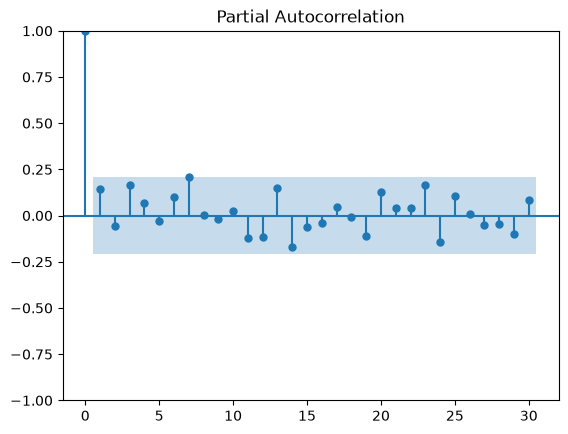

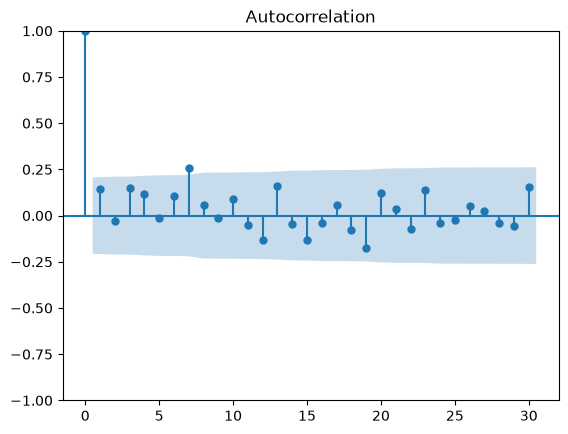

In [13]:

# ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_pacf(new_df['Differenced'].dropna(),lags=30)
plt.show()

plot_acf(new_df['Differenced'].dropna(),lags=30)
plt.show()


In [14]:

# Train-Test Split (70% training, 30% testing)
split_ratio = 0.7
train_size = int(len(new_df) * split_ratio)
train_data, test_data = new_df[0:train_size], new_df[train_size:].copy()  # Use .copy() to avoid SettingWithCopyWarning

print("Training data\n")
print(train_data)
print(test_data)

Training data

               NAV   rollMean   rollStd  Differenced
Date                                                
2017-01-01  12.865  12.137500  1.266288       -0.083
2017-02-01  13.739  12.449333  1.146319        0.874
2017-03-01  14.119  12.776250  0.994635        0.380
2017-04-01  14.677  13.082917  0.962992        0.558
2017-05-01  15.013  13.388083  0.944315        0.336
...            ...        ...       ...          ...
2021-10-01  31.120  25.286667  4.031531        0.989
2021-11-01  31.863  26.414917  3.793292        0.743
2021-12-01  31.089  27.276667  3.556064       -0.774
2022-01-01  31.879  28.104000  3.353512        0.790
2022-02-01  31.794  28.869917  3.015446       -0.085

[62 rows x 4 columns]
               NAV   rollMean   rollStd  Differenced
Date                                                
2022-03-01  29.806  29.327917  2.655839       -1.988
2022-04-01  31.369  29.904833  2.214153        1.563
2022-05-01  31.437  30.460167  1.544441        0.068
2022-06-

In [15]:


# ARIMA model on training data (replace p, d, q with identified values)
model = ARIMA(train_data['NAV'], order=(7, 1, 7))  # Adjust p, d, q based on your analysis
model_fit = model.fit()

# Forecast on testing data
forecast = model_fit.forecast(steps=len(test_data))

# Add forecast column to the original test DataFrame
test_data.loc[:, 'Forecast'] = forecast
print(test_data)


d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


               NAV   rollMean   rollStd  Differenced   Forecast
Date                                                           
2022-03-01  29.806  29.327917  2.655839       -1.988  32.076600
2022-04-01  31.369  29.904833  2.214153        1.563  31.907722
2022-05-01  31.437  30.460167  1.544441        0.068  32.879724
2022-06-01  30.620  30.761333  1.097275       -0.817  32.770097
2022-07-01  29.613  30.876250  0.853705       -1.007  32.750157
2022-08-01  32.354  31.089583  0.878184        2.741  32.814692
2022-09-01  33.210  31.346167  1.012223        0.856  33.123689
2022-10-01  32.565  31.466583  1.067322       -0.645  32.721585
2022-11-01  34.061  31.649750  1.303917        1.496  32.541032
2022-12-01  35.220  31.994000  1.643509        1.159  32.982649
2023-01-01  34.907  32.246333  1.844417       -0.313  32.649732
2023-02-01  34.362  32.460333  1.933967       -0.545  32.601923
2023-03-01  34.587  32.858750  1.826942        0.225  32.578528
2023-04-01  34.705  33.136750  1.833446 

d:\notebook\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


               NAV   Forecast
Date                         
2022-03-01  29.806  32.076600
2022-04-01  31.369  31.907722
2022-05-01  31.437  32.879724
2022-06-01  30.620  32.770097
2022-07-01  29.613  32.750157
               NAV   Forecast
Date                         
2024-02-01  47.776  32.805999
2024-03-01  48.876  32.834753
2024-04-01  49.494  32.415115
2024-05-01  50.750  32.997775
2024-06-01  52.509  32.694559
               NAV   rollMean   rollStd  Differenced   Forecast
Date                                                           
2022-03-01  29.806  29.327917  2.655839       -1.988  32.076600
2022-04-01  31.369  29.904833  2.214153        1.563  31.907722
2022-05-01  31.437  30.460167  1.544441        0.068  32.879724
2022-06-01  30.620  30.761333  1.097275       -0.817  32.770097
2022-07-01  29.613  30.876250  0.853705       -1.007  32.750157


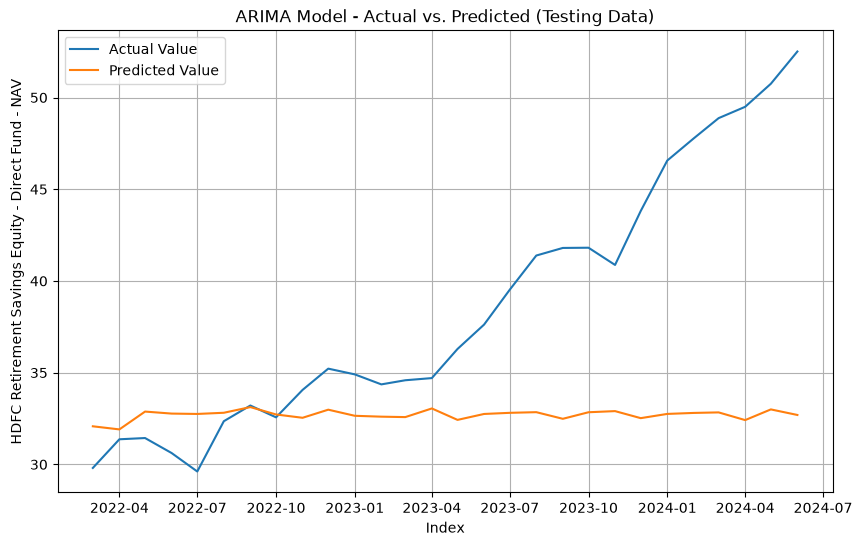

In [16]:

# Print actual and predicted values for testing data (optional)
selected_columns = ['NAV', 'Forecast']
print(test_data[selected_columns].head())
print(test_data[selected_columns].tail())
print(test_data.head())

# Plot actual vs. predicted values on testing data
plt.figure(figsize=(10, 6))
plt.plot(test_data.index, test_data['NAV'], label='Actual Value')
plt.plot(test_data.index, test_data['Forecast'], label='Predicted Value')
plt.xlabel('Index')
plt.ylabel('HDFC Retirement Savings Equity - Direct Fund - NAV')
plt.title('ARIMA Model - Actual vs. Predicted (Testing Data)')
plt.legend()
plt.grid(True)
plt.show()

In [17]:



# Forecast for the next 60 months
model = ARIMA(new_df['NAV'], order=(7, 1, 7))  # Adjust p, d, q based on your analysis
model_fit = model.fit()

num_periods = 120
forecast = model_fit.forecast(steps=num_periods)

print(df.tail())

# Create a DataFrame for the forecasted data (assuming 'Date' is the index)
start_date = new_df.index[-1] + pd.DateOffset(months=1)  # Start from the last date in df, add 1 month
predicted_dates = pd.date_range(start=start_date, periods=num_periods, freq='ME')  # Use 'M' for monthly frequency
forecast_df = pd.DataFrame({'Date': predicted_dates, 'Forecast': forecast})

d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


           Date     NAV
2048 2024-06-24  54.273
2049 2024-06-25  54.589
2050 2024-06-26  54.545
2051 2024-06-27  54.528
2052 2024-06-28  54.463


d:\notebook\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                 Date   Forecast
2024-07-01 2024-07-31  54.113970
2024-08-01 2024-08-31  55.959551
2024-09-01 2024-09-30  56.681232
2024-10-01 2024-10-31  58.018576
2024-11-01 2024-11-30  59.075447
                 Date   Forecast
2034-02-01 2034-02-28  92.734705
2034-03-01 2034-03-31  92.779367
2034-04-01 2034-04-30  92.913792
2034-05-01 2034-05-31  92.791653
2034-06-01 2034-06-30  92.956606


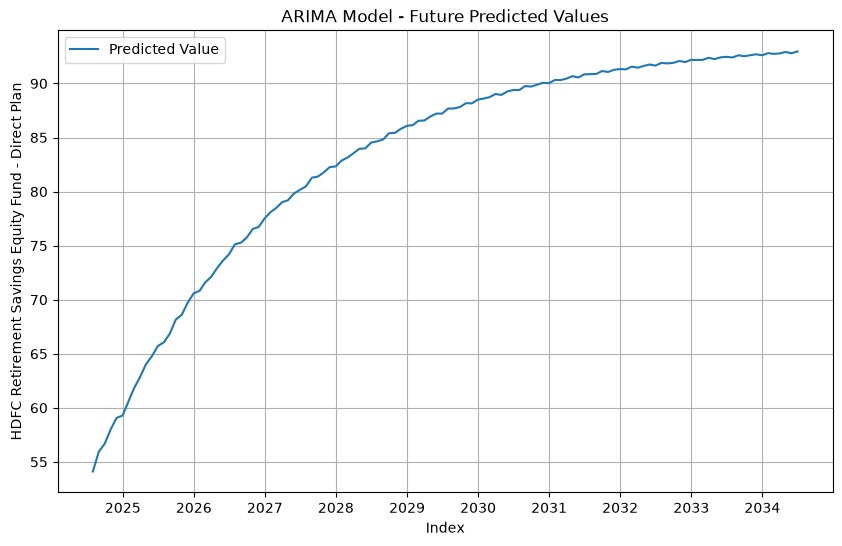

In [18]:

# Print the forecasted data 
print(forecast_df.head()) 
print(forecast_df.tail()) 

# Now plot future predictions
plt.figure(figsize=(10, 6))
plt.plot(forecast_df.Date, forecast_df['Forecast'], label='Predicted Value')
plt.xlabel('Index')
plt.ylabel('HDFC Retirement Savings Equity Fund - Direct Plan')
plt.title('ARIMA Model - Future Predicted Values')
plt.legend()
plt.grid(True)
plt.show()


In [19]:

# sarimax
# Create a copy of the test DF - Will be used for SARIMAX
arima_sarimax_df = test_data.copy()

# Create a new column with 12-month difference
new_df['Differenced'] = new_df['NAV'].diff(periods=12)

# Check stationarity of the differenced series (ADF test)
new_df = new_df.dropna()

adf_result = adfuller(new_df['Differenced'])
print(f"ADF Statistic (Differenced): {adf_result[0]}")
print(f"p-value (Differenced): {adf_result[1]}")

# H0: Data is not stationary
if adf_result[1] < 0.05:
    print("We reject the null hypothesis - This suggests that the data might be stationary.")
else:
    print("We fail reject the null hypothesis - This indicates that the data is likely non-stationary and might require further transformations (e.g., differencing) before using some time series analysis methods.")


ADF Statistic (Differenced): -0.10151224519906901
p-value (Differenced): 0.9492876995493204
We fail reject the null hypothesis - This indicates that the data is likely non-stationary and might require further transformations (e.g., differencing) before using some time series analysis methods.


In [20]:



# Train-Test Split (70% training, 30% testing)
split_ratio = 0.7
train_size = int(len(new_df) * split_ratio)
train_data, test_data = new_df[0:train_size], new_df[train_size:].copy()  # Use .copy() to avoid SettingWithCopyWarning

# SARIMA model on training data (replace p, d, q with identified values)
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    train_data['NAV'],
    order=(7, 1, 7),  # Adjust p, d, q based on your analysis
    seasonal_order=(7, 1, 7, 12)  # Seasonal difference of 12
)

model_fit = model.fit()

d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
d:\notebook\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
d:\notebook\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization

*** SARIMAX ***
               NAV   rollMean   rollStd  Differenced   Forecast  \
Date                                                              
2022-03-01  29.806  29.327917  2.655839       -1.988  32.076600   
2022-04-01  31.369  29.904833  2.214153        1.563  31.907722   
2022-05-01  31.437  30.460167  1.544441        0.068  32.879724   
2022-06-01  30.620  30.761333  1.097275       -0.817  32.770097   
2022-07-01  29.613  30.876250  0.853705       -1.007  32.750157   

            Forecast_sarimax  
Date                          
2022-03-01               NaN  
2022-04-01               NaN  
2022-05-01               NaN  
2022-06-01               NaN  
2022-07-01          29.31199  
               NAV   rollMean   rollStd  Differenced   Forecast  \
Date                                                              
2024-02-01  47.776  40.562750  4.269050        1.212  32.805999   
2024-03-01  48.876  41.753500  4.440092        1.100  32.834753   
2024-04-01  49.494  42.985917

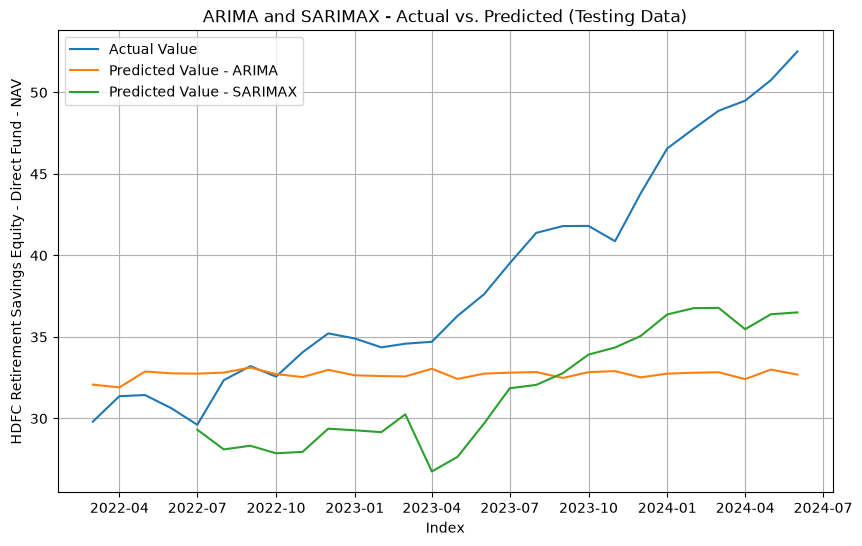

In [21]:



# Forecast on testing data
forecast_sarimax = model_fit.forecast(steps=len(test_data))

# Add forecast column to the original test DataFrame
test_data.loc[:, 'Forecast_sarimax'] = forecast_sarimax
arima_sarimax_df.loc[:, 'Forecast_sarimax'] = forecast_sarimax
print("*** SARIMAX ***")
print(arima_sarimax_df.head())
print(arima_sarimax_df.tail())

# Plot actual vs. predicted values on testing data
plt.figure(figsize=(10, 6))
plt.plot(arima_sarimax_df.index, arima_sarimax_df['NAV'], label='Actual Value')
plt.plot(arima_sarimax_df.index, arima_sarimax_df['Forecast'], label='Predicted Value - ARIMA')
plt.plot(arima_sarimax_df.index, arima_sarimax_df['Forecast_sarimax'], label='Predicted Value - SARIMAX')
plt.xlabel('Index')
plt.ylabel('HDFC Retirement Savings Equity - Direct Fund - NAV')
plt.title('ARIMA and SARIMAX - Actual vs. Predicted (Testing Data)')
plt.legend()
plt.grid(True)
plt.show()


In [22]:


# sarimax Forecast for the next few months
model_fit = model.fit()  # Refine the model using all data

forecast = model_fit.forecast(steps=num_periods)

# Create a DataFrame for the forecasted data (assuming 'Date' is the index)
start_date = new_df.index[-1] + pd.DateOffset(months=1)
predicted_dates = pd.date_range(start=start_date, periods=num_periods, freq='ME')

# Save a copy of ARIMA future_df for SARIMAX
forecast_df_sarimax = forecast_df.copy()

forecast_df = pd.DataFrame({'Date': predicted_dates, 'Forecast_sarimax': forecast})

# Forecast for the next few months
model = SARIMAX(
    new_df['NAV'],
    order=(7, 1, 7),  # Adjust p, d, q based on your analysis
    seasonal_order=(7, 1, 7, 12)  # Seasonal difference of 12
)

model_fit = model.fit()

forecast = model_fit.forecast(steps=num_periods)

print(new_df.tail())

d:\notebook\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
d:\notebook\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
d:\notebook\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequen

               NAV   rollMean   rollStd  Differenced
Date                                                
2024-02-01  47.776  40.562750  4.269050       13.414
2024-03-01  48.876  41.753500  4.440092       14.289
2024-04-01  49.494  42.985917  4.357505       14.789
2024-05-01  50.750  44.190667  4.337313       14.457
2024-06-01  52.509  45.431333  4.415862       14.888


                 Date   Forecast  Forecast_sarimax
2024-07-01 2024-07-31  54.113970         54.062742
2024-08-01 2024-08-31  55.959551         55.952066
2024-09-01 2024-09-30  56.681232         56.570876
2024-10-01 2024-10-31  58.018576         57.633051
2024-11-01 2024-11-30  59.075447         59.147385
                 Date   Forecast  Forecast_sarimax
2034-02-01 2034-02-28  92.734705        257.652568
2034-03-01 2034-03-31  92.779367        258.360669
2034-04-01 2034-04-30  92.913792        261.798861
2034-05-01 2034-05-31  92.791653        264.606839
2034-06-01 2034-06-30  92.956606        267.177757


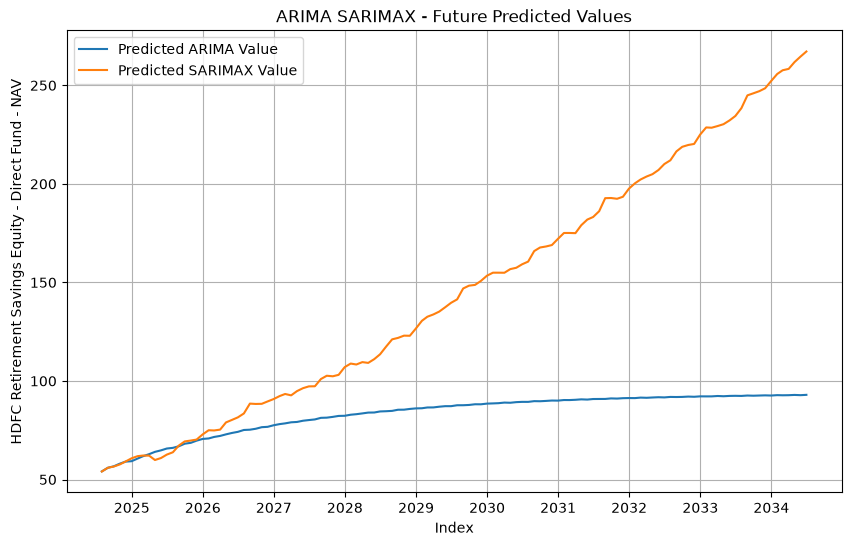

In [25]:


# Create a DataFrame for the forecasted data (assuming 'Date' is the index)
start_date = new_df.index[-1] + pd.DateOffset(months=1)  # Start from the last date in df, add 1 month
predicted_dates = pd.date_range(start=start_date, periods=num_periods, freq='ME')  # Use 'M' for monthly frequency
forecast_df = pd.DataFrame({'Date': predicted_dates, 'Forecast_sarimax': forecast})

# Add future  sarimax forecasts to the same DF which was used for ARIMA future forecasts
forecast_df_sarimax = pd.concat([forecast_df_sarimax, forecast_df[['Forecast_sarimax']]], axis=1)

# Print the forecasted data 
print(forecast_df_sarimax.head()) 
print(forecast_df_sarimax.tail()) 

forecast_df_sarimax.to_csv('forecast_df_sarimax.csv', index=False)

# Now plot future predictions
plt.figure(figsize=(10, 6))
plt.plot(forecast_df_sarimax.Date, forecast_df_sarimax['Forecast'], label='Predicted ARIMA Value')
plt.plot(forecast_df_sarimax.Date, forecast_df_sarimax['Forecast_sarimax'], label='Predicted SARIMAX Value')
plt.xlabel('Index')
plt.ylabel('HDFC Retirement Savings Equity - Direct Fund - NAV')
plt.title('ARIMA SARIMAX - Future Predicted Values')
plt.legend()
plt.grid(True)
plt.show()

